In [1]:
import matplotlib.pyplot as plt

from baymorph import SyntheticSersic

In [2]:
galaxy = SyntheticSersic(
    flux=10000,
    re=10,
    n=4,
    q=0.7,
    theta=0.5,
    x0=50,
    y0=50,
)

image = galaxy.render(
    shape=(100, 100)
)

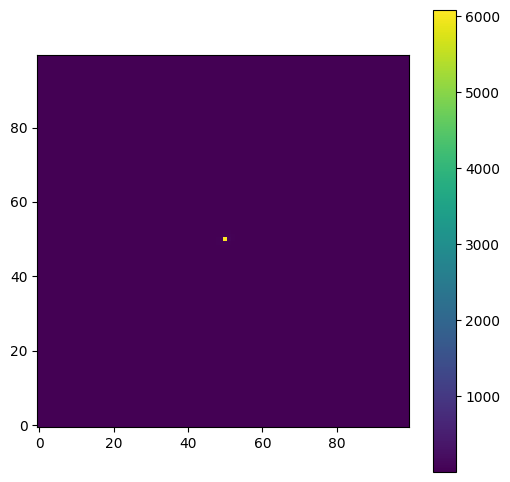

In [3]:
plt.figure(figsize=(6, 6))

plt.imshow(
    image,
    origin="lower",
)

plt.colorbar()

plt.show()

In [4]:
image.sum()

np.float64(9999.999999999996)

In [5]:
from baymorph import (
    DynestyFluxFitter,
    SersicModel,
    make_constant_noise_map,
)

In [6]:
true_flux = 1000.0

data = SersicModel(
    flux=true_flux,
    re=8.0,
    n=2.0,
    q=0.8,
    theta=0.0,
    x0=30.0,
    y0=30.0,
).render(
    shape=(60, 60)
)

In [7]:
noise = make_constant_noise_map(
    data.shape,
    sigma=1.0,
)

In [8]:
def model_factory(flux):

    return SersicModel(
        flux=flux,
        re=8.0,
        n=2.0,
        q=0.8,
        theta=0.0,
        x0=30.0,
        y0=30.0,
    )

In [9]:
fitter = DynestyFluxFitter(
    model_factory=model_factory,
    data=data,
    noise=noise,
    flux_min=100.0,
    flux_max=2000.0,
)

In [10]:
result = fitter.run(
    nlive=50
)

iter: 370 | +50 | bound: 6 | nc: 1 | ncall: 2355 | eff(%): 18.221 | loglstar:   -inf < -3308.179 <    inf | logz: -3312.636 +/-  0.273 | dlogz:  0.001 >  0.059                                       

In [11]:
result.flux_median

999.1386751572804

In [12]:
print("True flux:", true_flux)
print("Recovered flux:", result.flux_median)

True flux: 1000.0
Recovered flux: 999.1386751572804


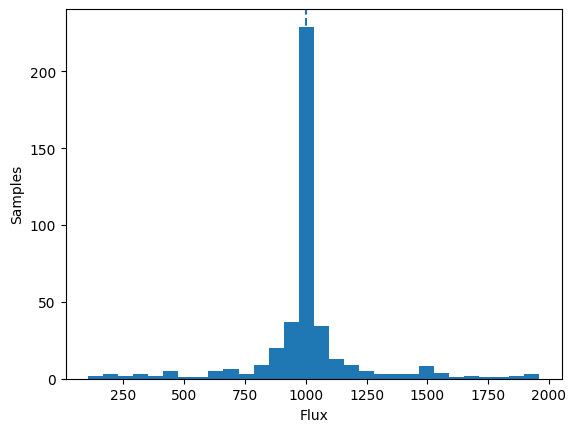

In [13]:
plt.hist(
    result.samples[:,0],
    bins=30,
)

plt.axvline(
    true_flux,
    linestyle="--",
)

plt.xlabel("Flux")
plt.ylabel("Samples")
plt.show()

In [14]:
from baymorph import DynestyFluxReFitter

In [15]:
true_flux = 1000.0
true_re = 8.0

data = SersicModel(
    flux=true_flux,
    re=true_re,
    n=2.0,
    q=0.8,
    theta=0.0,
    x0=30.0,
    y0=30.0,
).render(shape=(60, 60))

noise = make_constant_noise_map(
    data.shape,
    sigma=1.0,
)

In [16]:
def model_factory_flux_re(flux, re):
    return SersicModel(
        flux=flux,
        re=re,
        n=2.0,
        q=0.8,
        theta=0.0,
        x0=30.0,
        y0=30.0,
    )

In [17]:
fitter = DynestyFluxReFitter(
    model_factory=model_factory_flux_re,
    data=data,
    noise=noise,
    flux_min=100.0,
    flux_max=2000.0,
    re_min=2.0,
    re_max=20.0,
)

result_2d = fitter.run(nlive=100)

iter: 1000 | +100 | bound: 11 | nc: 1 | ncall: 4801 | eff(%): 23.399 | loglstar:   -inf < -3308.180 <    inf | logz: -3315.862 +/-  0.256 | dlogz:  0.001 >  0.109                                    

In [18]:
print("True flux:", true_flux)
print("Recovered flux:", result_2d.flux_median)

print("True Re:", true_re)
print("Recovered Re:", result_2d.re_median)

True flux: 1000.0
Recovered flux: 1008.6371032281247
True Re: 8.0
Recovered Re: 8.090462609706858


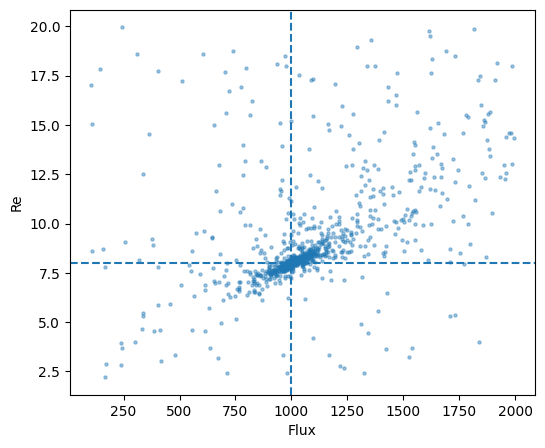

In [19]:
plt.figure(figsize=(6, 5))
plt.scatter(
    result_2d.samples[:, 0],
    result_2d.samples[:, 1],
    s=5,
    alpha=0.4,
)

plt.axvline(true_flux, linestyle="--")
plt.axhline(true_re, linestyle="--")

plt.xlabel("Flux")
plt.ylabel("Re")
plt.show()